# Phase 3.3 — Visualizar meta-máscara Adam (`merged_p33_adam`)

Análise do run **`20261014_140811_phase3_3_merged_p33_adam`** (identity ensemble + SSIM, otimizador Adam, `fr_preset=small`).

1. Carrega o checkpoint (run fixo ou `LATEST_phase3_3_merged_p33_adam.txt`).
2. Mostra curvas do `train_log.csv`.
3. Visualiza a máscara sozinha (magnitude DT-CWT L2/L3 + residual espacial).
4. Aplica em **3 faces** LFW (test) com L∞ e mostra antes / depois.
5. Mede **`cos_similarity`** (menor = melhor desID) e **SSIM**.
6. Avalia ~200 faces do pool de eval (LFW test ∪ CelebA holdout, mesmo `data_seed` / `celeba_train_frac`).

Para comparar com Protego depois do treino: `phase3_3_visualize_merged_identity_mask.ipynb`.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pytorch_msssim import ssim as calc_ssim

REPO_ROOT = Path("..").resolve()
PROTEGO_BASE = REPO_ROOT / "protego_base"
if str(PROTEGO_BASE) not in sys.path:
    sys.path.insert(0, str(PROTEGO_BASE))

from protego.FacialRecognition import FR
from protego.datasets import build_merged_frac_split, list_image_paths, resolve_split_dir
from protego.dtcwt_mask import DTCWTMetaMaskModule
from protego.quality_loss import apply_linf_budget
from protego.utils import load_imgs

MASK_ROOT = Path("/mnt/study-data/dcarvalho/tests")
METRICS_ROOT = Path("/mnt/study-data/dcarvalho/metrics")

# Pin this run (change RUN_ID or set to None to follow LATEST pointer).
RUN_ID = "20261014_140811_phase3_3_merged_p33_adam"
LATEST_PTR = MASK_ROOT / "LATEST_phase3_3_merged_p33_adam.txt"

N_IMAGES = 3
N_EVAL = 200
EVAL_BATCH = 16
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)
print("RUN_ID:", RUN_ID)
print("LATEST_PTR:", LATEST_PTR)

/home/dcarvalho/dtcwt_mask_optmization/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda:0
RUN_ID: 20261014_140811_phase3_3_merged_p33_adam
LATEST_PTR: /mnt/study-data/dcarvalho/tests/LATEST_phase3_3_merged_p33_adam.txt


/home/dcarvalho/dtcwt_mask_optmization/protego_base/protego/FaceDetection.py:48: FutureWarning: Decorating classes is deprecated and will be disabled in future versions. You should only decorate functions or methods. To preserve the current behavior of class decoration, you can directly decorate the `__init__` method and nothing else.
  @torch.no_grad()


## 1. Carregar checkpoint + summary

In [2]:
if RUN_ID:
    mask_path = MASK_ROOT / RUN_ID / "meta_mask.pt"
    metrics_dir = METRICS_ROOT / RUN_ID
else:
    assert LATEST_PTR.is_file(), f"Pointer not found: {LATEST_PTR}"
    mask_path = Path(LATEST_PTR.read_text(encoding="utf-8").strip())
    metrics_dir = METRICS_ROOT / mask_path.parent.name

assert mask_path.is_file(), f"Mask missing: {mask_path}"
assert metrics_dir.is_dir(), f"Metrics dir missing: {metrics_dir}"

ckpt = torch.load(mask_path, map_location="cpu", weights_only=False)
cfg = ckpt.get("config", {})
with open(metrics_dir / "summary.json", encoding="utf-8") as f:
    summary = json.load(f)

img_size = int(ckpt.get("img_size", cfg.get("img_size", 224)))
fr_name = cfg.get("fr_model", "ir50_arcface_casia")
train_frs = cfg.get("train_fr_names", [fr_name])
epsilon = float(cfg.get("epsilon", 16 / 255))
min_ssim = float(cfg.get("min_ssim", 0.95))
data_seed = int(cfg.get("data_seed") or 42)
celeba_frac = float(cfg.get("celeba_train_frac") or 0.5)

print("run_id       :", cfg.get("run_id") or mask_path.parent.name)
print("phase        :", cfg.get("phase"), "| phase33=", cfg.get("phase33"))
print("optimizer    :", cfg.get("optimizer"), "| lr=", cfg.get("lr"))
print("mask_path    :", mask_path)
print("metrics_dir  :", metrics_dir)
print("dataset      :", cfg.get("dataset"), "| n_train=", cfg.get("n_train_total"))
print("celeba_frac  :", celeba_frac, "| data_seed=", data_seed)
print("fr_preset    :", cfg.get("fr_preset"), "| n_frs=", cfg.get("n_frs"))
print("train_frs    :", train_frs)
print("eval FR      :", fr_name, "(first ensemble member for notebook metrics)")
print("epsilon      :", epsilon, "| min_ssim=", min_ssim)
print("final_loss   :", summary.get("final_loss"))
print("final_cos_sim:", summary.get("final_cos_similarity"), "(lower=better; last train batch)")
print("final_ssim   :", summary.get("final_ssim"))
print("steps        :", summary.get("steps"), "| elapsed_s=", round(summary.get("elapsed_seconds", 0), 1))

for k, v in ckpt["meta_mask"].items():
    print(f"  {k}: shape={tuple(v.shape)}  |mean|={v.abs().mean():.4f}  max|={v.abs().max():.4f}")

mask_mod = DTCWTMetaMaskModule(channels=3, img_size=img_size, J=3, editable_levels=(2, 3))
mask_mod.load_meta_mask_state(ckpt["meta_mask"])
mask_mod = mask_mod.to(DEVICE).eval()
for p in mask_mod.parameters():
    p.requires_grad_(False)

run_id       : 20261014_140811_phase3_3_merged_p33_adam
phase        : phase3_3 | phase33= True
optimizer    : adam | lr= 0.01
mask_path    : /mnt/study-data/dcarvalho/tests/20261014_140811_phase3_3_merged_p33_adam/meta_mask.pt
metrics_dir  : /mnt/study-data/dcarvalho/metrics/20261014_140811_phase3_3_merged_p33_adam
dataset      : merged_lfw_celeba | n_train= 20587
celeba_frac  : 0.5 | data_seed= 42
fr_preset    : small | n_frs= 3
train_frs    : ['ir50_arcface_casia', 'mobilefacenet_arcface_casia', 'ir18_adaface_webface']
eval FR      : ir50_arcface_casia (first ensemble member for notebook metrics)
epsilon      : 0.06274509803921569 | min_ssim= 0.95
final_loss   : 0.998566746711731
final_cos_sim: 0.9985667069753011 (lower=better; last train batch)
final_ssim   : 0.9838678240776062
steps        : 51470 | elapsed_s= 29718.9
  delta_mag_2: shape=(1, 3, 6, 56, 56)  |mean|=0.0130  max|=0.1144
  delta_phase_2: shape=(1, 3, 6, 56, 56)  |mean|=5.9311  max|=34.6303
  delta_mag_3: shape=(1, 3, 

## 2. Curvas de treino (`train_log.csv`)

`cos_similarity` menor = melhor desidentificação; SSIM maior = melhor qualidade.

rows: 51470 | columns: ['epoch', 'step', 'loss', 'disp_loss', 'disp_k_loss', 'disp_batch_loss', 'cos_similarity', 'gram_offdiag_abs_mean', 'feat_norm_mean', 'ssim', 'percep_term', 'percep_weight', 'linf_max', 'n_frs', 'lr', 'optimizer', 'seconds']


,epoch,step,loss,disp_loss,disp_k_loss,disp_batch_loss,cos_similarity,gram_offdiag_abs_mean,feat_norm_mean,ssim,percep_term,percep_weight,linf_max,n_frs,lr,optimizer,seconds
51465,5,51466,6.076076,0.0,0.0,0.0,0.994594,0.0,0.0,0.930150,5.081482,256.0,0.062745,3,0.01,adam,29716.660486
51466,5,51467,0.997174,0.0,0.0,0.0,0.997174,0.0,0.0,0.964871,0.000000,128.0,0.062745,3,0.01,adam,29717.187214
51467,5,51468,0.998724,0.0,0.0,0.0,0.998724,0.0,0.0,0.988654,0.000000,64.0,0.062745,3,0.01,adam,29717.703457
51468,5,51469,0.998737,0.0,0.0,0.0,0.998737,0.0,0.0,0.985594,0.000000,32.0,0.062745,3,0.01,adam,29718.173798
51469,5,51470,0.998567,0.0,0.0,0.0,0.998567,0.0,0.0,0.983868,0.000000,16.0,0.062745,3,0.01,adam,29718.675247


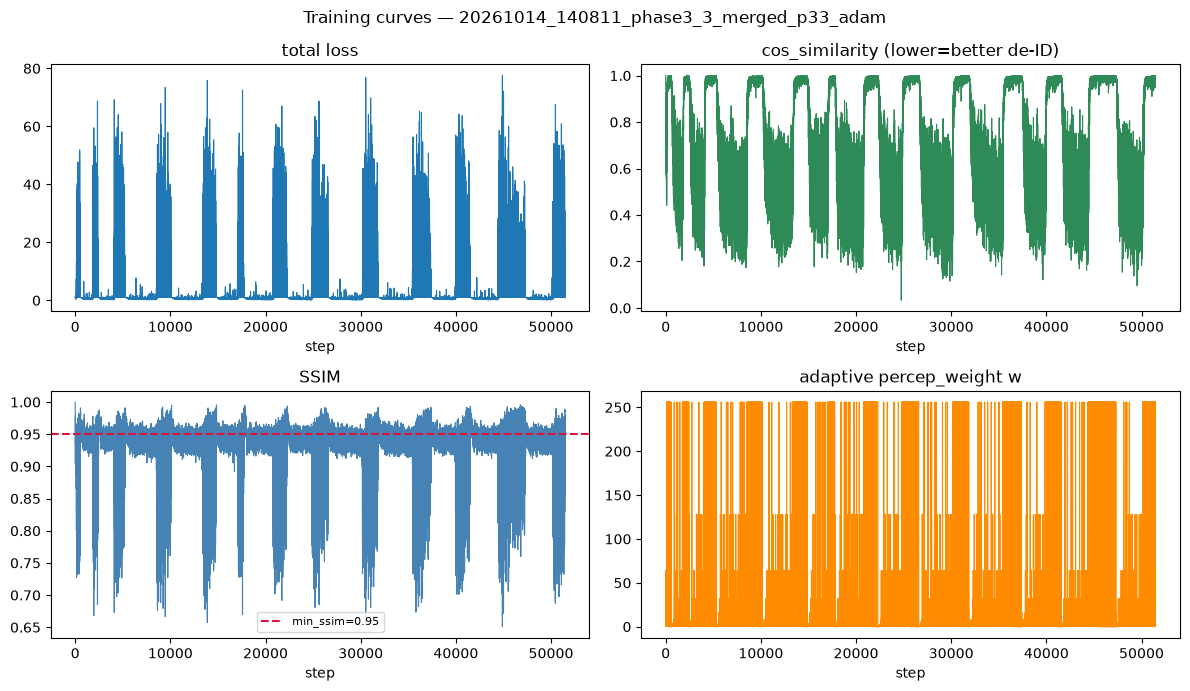


End-of-train means (last 100 steps):
  loss              : 8.6003
  cos_similarity    : 0.9895
  ssim              : 0.8971
  percep_weight     : 103.5881
  linf_max          : 0.0627


In [3]:
log_csv = metrics_dir / "train_log.csv"
df_log = pd.read_csv(log_csv)
print("rows:", len(df_log), "| columns:", list(df_log.columns))
display(df_log.tail(5))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.ravel()

axes[0].plot(df_log["step"], df_log["loss"], lw=0.8)
axes[0].set_title("total loss")
axes[0].set_xlabel("step")

axes[1].plot(df_log["step"], df_log["cos_similarity"], lw=0.8, color="seagreen")
axes[1].set_title("cos_similarity (lower=better de-ID)")
axes[1].set_xlabel("step")

axes[2].plot(df_log["step"], df_log["ssim"], lw=0.8, color="steelblue")
axes[2].axhline(min_ssim, color="crimson", ls="--", label=f"min_ssim={min_ssim}")
axes[2].set_title("SSIM")
axes[2].legend(fontsize=8)
axes[2].set_xlabel("step")

axes[3].plot(df_log["step"], df_log["percep_weight"], lw=0.8, color="darkorange")
axes[3].set_title("adaptive percep_weight w")
axes[3].set_xlabel("step")

fig.suptitle(f"Training curves — {mask_path.parent.name}", fontsize=12)
plt.tight_layout()
plt.show()

print("\nEnd-of-train means (last 100 steps):")
tail = df_log.tail(100)
for col in ["loss", "cos_similarity", "ssim", "percep_weight", "linf_max"]:
    if col in tail.columns:
        print(f"  {col:18s}: {tail[col].mean():.4f}")

## 3. Máscara sozinha (sem face)

- Magnitude de ΔW nos níveis 2 e 3.
- Residual espacial em cinza médio, com bound L∞ do treino.

/tmp/ipykernel_3926298/2626759315.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


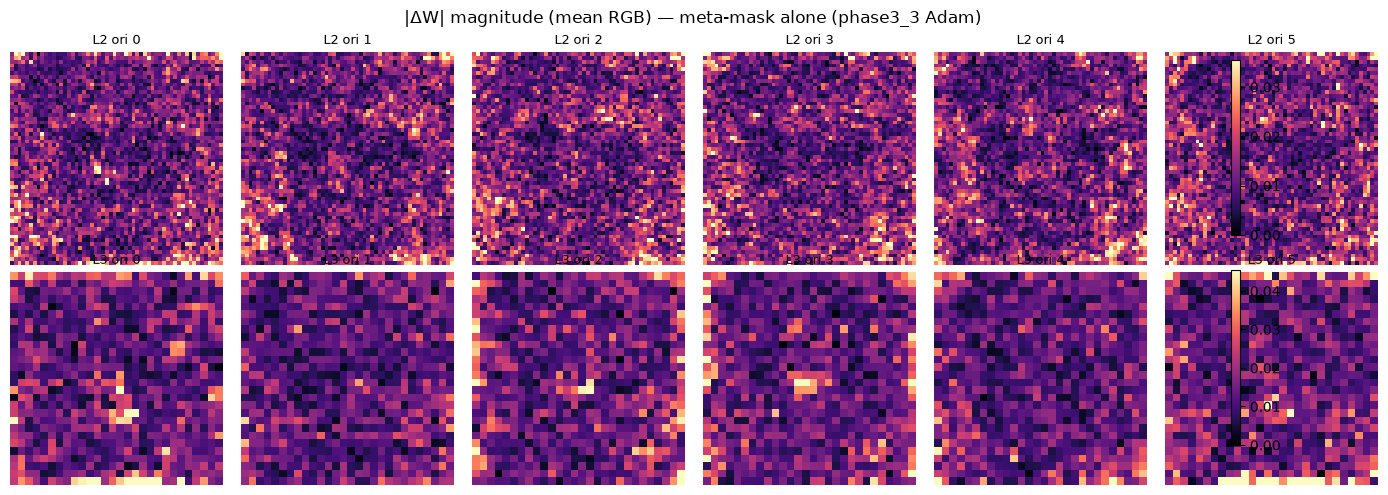

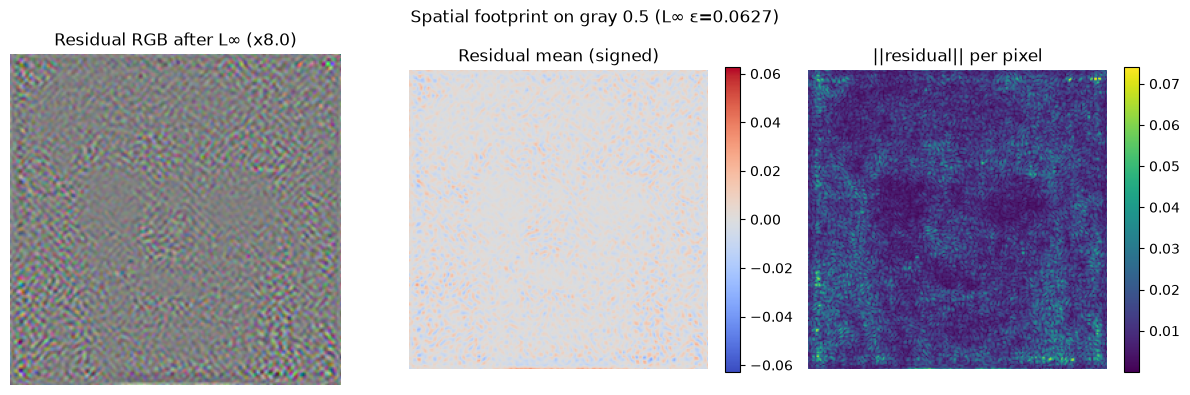

residual (after L∞): mean=-0.00000  std=0.00885  linf=0.06275  (budget=0.06275)


In [4]:
@torch.no_grad()
def show_mask_alone(module: DTCWTMetaMaskModule, epsilon: float, img_size: int = 224):
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for row, level in enumerate((2, 3)):
        mag = module.delta_mag[str(level)][0].detach().cpu().abs().mean(dim=0).numpy()
        vmax = np.percentile(mag, 99) + 1e-8
        for o in range(6):
            ax = axes[row, o]
            im = ax.imshow(mag[o], cmap="magma", vmin=0, vmax=vmax)
            ax.set_title(f"L{level} ori {o}", fontsize=9)
            ax.axis("off")
        fig.colorbar(im, ax=axes[row, :].tolist(), fraction=0.02, pad=0.02)
    fig.suptitle("|ΔW| magnitude (mean RGB) — meta-mask alone (phase3_3 Adam)", fontsize=12)
    plt.tight_layout()
    plt.show()

    gray = torch.full((1, 3, img_size, img_size), 0.5, device=DEVICE)
    recon = module(gray)
    prot, residual = apply_linf_budget(recon, gray, epsilon)
    residual = residual[0].detach().cpu()
    res_rgb = residual.permute(1, 2, 0).numpy()
    amp = min(10.0, 0.5 / (residual.abs().max().item() + 1e-8))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(np.clip(res_rgb * amp + 0.5, 0, 1))
    axes[0].set_title(f"Residual RGB after L∞ (x{amp:.1f})")
    axes[0].axis("off")

    res_mean = residual.mean(dim=0).numpy()
    lim = max(float(res_mean.std() * 3), epsilon)
    im1 = axes[1].imshow(res_mean, cmap="coolwarm", vmin=-lim, vmax=lim)
    axes[1].set_title("Residual mean (signed)")
    axes[1].axis("off")
    fig.colorbar(im1, ax=axes[1], fraction=0.046)

    mag_map = residual.norm(dim=0).numpy()
    im2 = axes[2].imshow(mag_map, cmap="viridis")
    axes[2].set_title("||residual|| per pixel")
    axes[2].axis("off")
    fig.colorbar(im2, ax=axes[2], fraction=0.046)

    fig.suptitle(f"Spatial footprint on gray 0.5 (L∞ ε={epsilon:.4f})")
    plt.tight_layout()
    plt.show()

    print(
        f"residual (after L∞): mean={residual.mean():.5f}  std={residual.std():.5f}  "
        f"linf={residual.abs().max():.5f}  (budget={epsilon:.5f})"
    )


show_mask_alone(mask_mod, epsilon=epsilon, img_size=img_size)

## 4. Antes / depois em 3 imagens + cos_similarity + SSIM

$$X_{\mathrm{prot}} = X + \mathrm{clamp}(\hat{X}-X, -\varepsilon, \varepsilon)$$

Métrica de desidentificação: **`cos_similarity`** (menor = melhor).

In [5]:
fr = FR(model_name=fr_name, device=DEVICE)
fr.fr_model.model.eval()
for p in fr.fr_model.model.parameters():
    p.requires_grad_(False)

split_dir = resolve_split_dir("lfw_frontal", "test")
all_paths = list_image_paths(split_dir)
idxs = np.linspace(0, len(all_paths) - 1, num=N_IMAGES, dtype=int)
paths = [all_paths[i] for i in idxs]
print("images:")
for p in paths:
    print(" -", p)

imgs = load_imgs(img_paths=paths, img_sz=img_size, drange=1, device=DEVICE)

with torch.no_grad():
    recon = mask_mod(imgs)
    protected, residual = apply_linf_budget(recon, imgs, epsilon)
    feat_orig = F.normalize(fr(imgs), p=2, dim=1)
    feat_prot = F.normalize(fr(protected), p=2, dim=1)
    cos_sim = (feat_orig * feat_prot).sum(dim=1)
    ssims = []
    for i in range(N_IMAGES):
        s = calc_ssim(
            protected[i : i + 1], imgs[i : i + 1], data_range=1.0, size_average=True
        )
        ssims.append(float(s.cpu()))
    ssims = np.array(ssims)

print("\nMetrics (cos_similarity: lower = better de-identification):")
for i, p in enumerate(paths):
    print(
        f"  [{i}] {Path(p).name}:  cos_similarity={cos_sim[i].item():.4f}  "
        f"SSIM={ssims[i]:.4f}  linf={residual[i].abs().max().item():.4f}"
    )
print(
    f"  mean cos_similarity={cos_sim.mean().item():.4f}  mean SSIM={ssims.mean():.4f}  "
    f"(target min_ssim={min_ssim})"
)

images:
 - /mnt/databases/faces/lfw_frontal/faces_test/img_000000.jpg
 - /mnt/databases/faces/lfw_frontal/faces_test/img_006572.jpg
 - /mnt/databases/faces/lfw_frontal/faces_test/img_013231.jpg

Metrics (cos_similarity: lower = better de-identification):
  [0] img_000000.jpg:  cos_similarity=0.9949  SSIM=0.9590  linf=0.0627
  [1] img_006572.jpg:  cos_similarity=0.9421  SSIM=0.9527  linf=0.0627
  [2] img_013231.jpg:  cos_similarity=0.9968  SSIM=0.9561  linf=0.0627
  mean cos_similarity=0.9779  mean SSIM=0.9559  (target min_ssim=0.95)


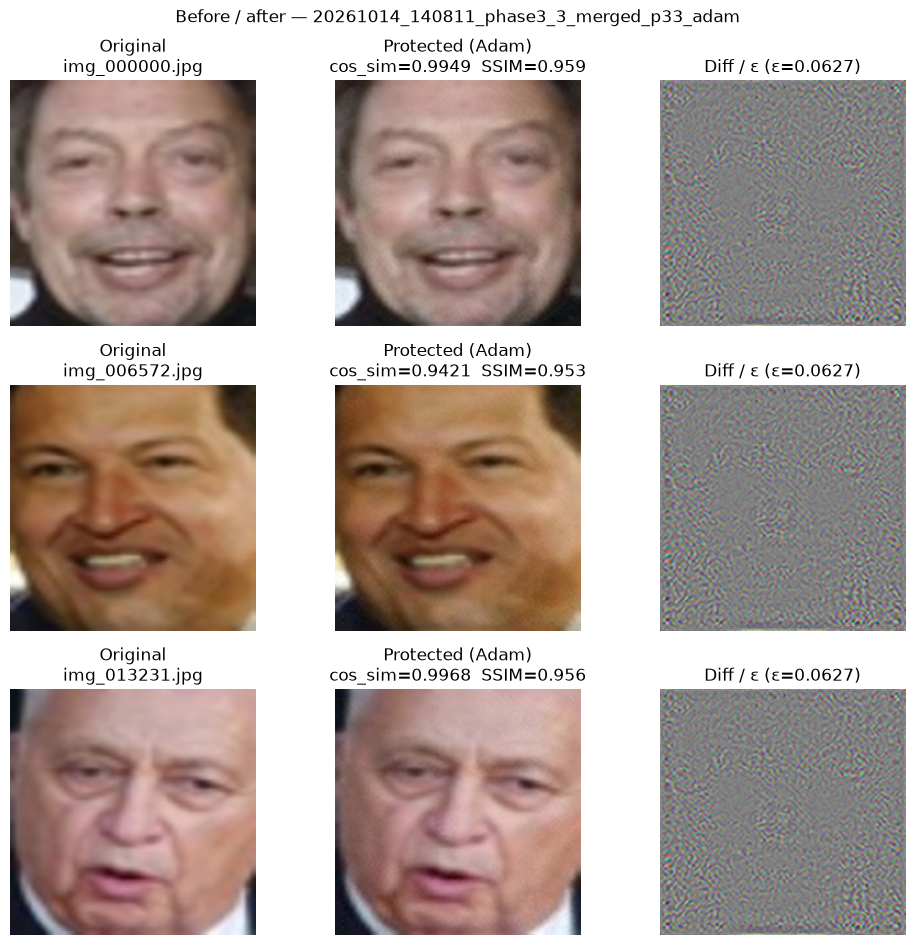

In [6]:
def to_np_img(t: torch.Tensor) -> np.ndarray:
    return t.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()


fig, axes = plt.subplots(N_IMAGES, 3, figsize=(10, 3.2 * N_IMAGES))
if N_IMAGES == 1:
    axes = np.expand_dims(axes, 0)

for i in range(N_IMAGES):
    orig = to_np_img(imgs[i])
    prot = to_np_img(protected[i])
    diff = np.clip((prot - orig) / (epsilon + 1e-8) * 0.5 + 0.5, 0, 1)

    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f"Original\n{Path(paths[i]).name}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(prot)
    axes[i, 1].set_title(
        f"Protected (Adam)\ncos_sim={cos_sim[i].item():.4f}  SSIM={ssims[i]:.3f}"
    )
    axes[i, 1].axis("off")

    axes[i, 2].imshow(diff)
    axes[i, 2].set_title(f"Diff / ε (ε={epsilon:.4f})")
    axes[i, 2].axis("off")

fig.suptitle(f"Before / after — {mask_path.parent.name}", fontsize=12)
plt.tight_layout()
plt.show()

## 5. Tabela resumo (3 imagens)

In [7]:
rows = []
for i, p in enumerate(paths):
    rows.append({
        "image": Path(p).name,
        "cos_similarity": float(cos_sim[i]),
        "ssim": float(ssims[i]),
        "linf_pixel": float(residual[i].abs().max()),
        "l2_pixel": float((protected[i] - imgs[i]).pow(2).mean().sqrt()),
    })
df = pd.DataFrame(rows)
display(df)
print("mean cos_similarity (lower=better):", df["cos_similarity"].mean())
print("mean SSIM:", df["ssim"].mean(), "| target min_ssim:", min_ssim)

,image,cos_similarity,ssim,linf_pixel,l2_pixel
0,img_000000.jpg,0.994891,0.958981,0.062745,0.008849
1,img_006572.jpg,0.942096,0.952712,0.062745,0.008847
2,img_013231.jpg,0.996803,0.956097,0.062745,0.008849


mean cos_similarity (lower=better): 0.977929929892222
mean SSIM: 0.955929676691691 | target min_ssim: 0.95


## 6. Avaliação em lote (~200 imagens)

Pool regenerável com o mesmo split do treino: LFW `faces_test` ∪ CelebA holdout
(`data_seed` + `celeba_train_frac` do config).

Reporta média / std / percentis de SSIM, **`cos_similarity`** (menor = melhor), L∞ e L2.

split_stats: {'n_lfw_train': 8226, 'n_lfw_test': 2029, 'n_celeba_total': 24722, 'n_celeba_train': 12361, 'n_celeba_eval': 12361, 'n_train_total': 20587, 'n_eval_total': 14390}
Evaluating 200/14390 eval images
batch_size=16  fr=ir50_arcface_casia  epsilon=0.06275
  processed 16/200
  processed 32/200
  processed 48/200
  processed 64/200
  processed 80/200
  processed 96/200
  processed 112/200
  processed 128/200
  processed 144/200
  processed 160/200
  processed 176/200
  processed 192/200
  processed 200/200

=== Summary over 200 images ===
(cos_similarity: lower = better de-identification)


,mean,std,min,p25,median,p75,max
metric,,,,,,,
ssim,0.9697,0.0079,0.9410,0.9647,0.9707,0.9757,0.9879
cos_similarity,0.9977,0.0017,0.9878,0.9972,0.9981,0.9987,1.0000
linf_pixel,0.0627,0.0000,0.0627,0.0627,0.0627,0.0627,0.0627
l2_pixel,0.0088,0.0001,0.0078,0.0088,0.0088,0.0088,0.0089



mean SSIM          : 0.9697  (target min_ssim=0.95)
mean cos_similarity: 0.9977  (lower=better)
frac SSIM >= min_ssim: 0.990
mean linf_pixel    : 0.06275  (budget=0.06275)


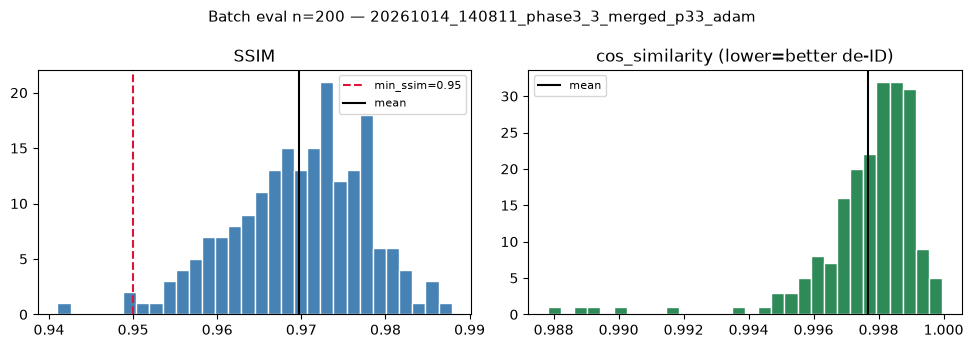


First 10 rows:


,image,cos_similarity,ssim,linf_pixel,l2_pixel
0,img_000000.jpg,0.994891,0.958981,0.062745,0.008849
1,img_000429.jpg,0.998254,0.959573,0.062745,0.008823
2,img_000883.jpg,0.996727,0.952657,0.062745,0.008850
3,img_001368.jpg,0.995276,0.950718,0.062745,0.008850
4,img_001786.jpg,0.996747,0.956588,0.062745,0.008839
5,img_002303.jpg,0.996400,0.958675,0.062745,0.008789
6,img_002746.jpg,0.989007,0.950041,0.062745,0.008850
7,img_003222.jpg,0.999020,0.966449,0.062745,0.008842
8,img_003813.jpg,0.995841,0.958884,0.062745,0.008818
9,img_004156.jpg,0.997405,0.962377,0.062745,0.008813


In [8]:
_train, eval_paths_all, split_stats = build_merged_frac_split(
    celeba_train_frac=celeba_frac, data_seed=data_seed
)
print("split_stats:", split_stats)

n_avail = len(eval_paths_all)
n_use = min(N_EVAL, n_avail)
eval_idxs = np.linspace(0, n_avail - 1, num=n_use, dtype=int)
eval_paths = [eval_paths_all[i] for i in eval_idxs]
print(f"Evaluating {n_use}/{n_avail} eval images")
print(f"batch_size={EVAL_BATCH}  fr={fr_name}  epsilon={epsilon:.5f}")

rows_eval = []
with torch.no_grad():
    for start in range(0, n_use, EVAL_BATCH):
        batch_paths = eval_paths[start : start + EVAL_BATCH]
        batch = load_imgs(img_paths=batch_paths, img_sz=img_size, drange=1, device=DEVICE)
        recon = mask_mod(batch)
        prot, res = apply_linf_budget(recon, batch, epsilon)

        feat_o = F.normalize(fr(batch), p=2, dim=1)
        feat_p = F.normalize(fr(prot), p=2, dim=1)
        sim = (feat_o * feat_p).sum(dim=1)

        for i, p in enumerate(batch_paths):
            ssim_i = float(
                calc_ssim(
                    prot[i : i + 1], batch[i : i + 1], data_range=1.0, size_average=True
                ).cpu()
            )
            rows_eval.append({
                "image": Path(p).name,
                "cos_similarity": float(sim[i].cpu()),
                "ssim": ssim_i,
                "linf_pixel": float(res[i].abs().max().cpu()),
                "l2_pixel": float((prot[i] - batch[i]).pow(2).mean().sqrt().cpu()),
            })
        print(f"  processed {min(start + EVAL_BATCH, n_use)}/{n_use}")

df_eval = pd.DataFrame(rows_eval)


def _stats(series: pd.Series) -> dict:
    return {
        "mean": float(series.mean()),
        "std": float(series.std(ddof=0)),
        "min": float(series.min()),
        "p25": float(series.quantile(0.25)),
        "median": float(series.median()),
        "p75": float(series.quantile(0.75)),
        "max": float(series.max()),
    }


metric_cols = ["ssim", "cos_similarity", "linf_pixel", "l2_pixel"]
summary_eval = pd.DataFrame({c: _stats(df_eval[c]) for c in metric_cols}).T
summary_eval.index.name = "metric"

print("\n=== Summary over", len(df_eval), "images ===")
print("(cos_similarity: lower = better de-identification)")
display(summary_eval.round(4))
print(f"\nmean SSIM          : {df_eval['ssim'].mean():.4f}  (target min_ssim={min_ssim})")
print(f"mean cos_similarity: {df_eval['cos_similarity'].mean():.4f}  (lower=better)")
print(f"frac SSIM >= min_ssim: {(df_eval['ssim'] >= min_ssim).mean():.3f}")
print(f"mean linf_pixel    : {df_eval['linf_pixel'].mean():.5f}  (budget={epsilon:.5f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df_eval["ssim"], bins=30, color="steelblue", edgecolor="white")
axes[0].axvline(min_ssim, color="crimson", ls="--", label=f"min_ssim={min_ssim}")
axes[0].axvline(df_eval["ssim"].mean(), color="black", ls="-", label="mean")
axes[0].set_title("SSIM")
axes[0].legend(fontsize=8)

axes[1].hist(df_eval["cos_similarity"], bins=30, color="seagreen", edgecolor="white")
axes[1].axvline(df_eval["cos_similarity"].mean(), color="black", ls="-", label="mean")
axes[1].set_title("cos_similarity (lower=better de-ID)")
axes[1].legend(fontsize=8)

fig.suptitle(f"Batch eval n={len(df_eval)} — {mask_path.parent.name}", fontsize=11)
plt.tight_layout()
plt.show()

print("\nFirst 10 rows:")
display(df_eval.head(10))